In [39]:
import igl
import meshplot as mp
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
import matplotlib.tri as mtri
from matplotlib.animation import FuncAnimation
from matplotlib.collections import PolyCollection 
import ipywidgets as widgets
from IPython.display import clear_output, display
import time
import threading
from typing import Tuple
from typing import List
%matplotlib widget

In [40]:



def vec2(x: float, y: float) -> np.ndarray:
    '''
    Creates (2,) ndarray
    '''
    return np.array([x, y], dtype=np.float64)


def hat(p: np.ndarray) -> np.ndarray:
    '''
    Rotates 2d vector by pi/2 counterclockwise
    '''
    return vec2(-p[1], p[0])

def compute_triangle_areas(V: np.ndarray, T: np.ndarray) -> np.ndarray:
    '''
    Computes area of each triangle in V, T mesh
    '''
    E = len(T) # no of triangles/elements
    A = np.zeros(E, dtype=np.float64)
    for e in range(E):
        # indecies of vertecies of current triangle
        i, j, k = T[e, :]   
        # coordinates of vertices
        xi, yi = V[i, :]
        xj, yj = V[j, :]
        xk, yk = V[k, :]
        # distances
        dx1 = xk - xj
        dy1 = yk - yj
        dx2 = xi - xj
        dy2 = yi - yj
        # area of current element
        A[e] =  (dx1*dy2 - dx2*dy1 ) / 2.0
    return A


def make_beam_mesh(width: int, height: int, shape: Tuple[int, int]) -> Tuple[np.ndarray, np.ndarray]:
    '''
    Creates a simple rectangular V, T mesh
    '''
    # mesh is centered around (0, 0)
    x0 = -width/2.0
    y0 = -height/2.0
    I, J = shape #resolution
    # distances between cells
    dx = width/float(I)
    dy = height/float(J)

    V = np.zeros(((I + 1)*(J + 1), 2), np.float64)
    # vecrorized double loop
    iy, ix = np.meshgrid(np.arange(J + 1), np.arange(I + 1), indexing='ij')
    V[:, 0] = x0 + ix.ravel()*dx
    V[:, 1] = y0 + iy.ravel()*dy
    
    T = np.zeros((2*I*J,3),dtype=np.int32)
    for j in range(J):
        for i in range(I):
            k00 = (i  ) + (j  )*(I+1)
            k01 = (i+1) + (j  )*(I+1)
            k10 = (i  ) + (j+1)*(I+1)
            k11 = (i+1) + (j+1)*(I+1)
            e = 2*(i + j*I)
            if (i+j+1)%2:
                T[e,  :] = (k00,k01,k11)
                T[e+1,:] = (k00,k11,k10)
            else:
                T[e,  :] = (k10,k00,k01)
                T[e+1,:] = (k10,k01,k11)  
    return V, T

class MeshInfo:
    def __init__(self, V: np.ndarray, T: np.ndarray):
        """
        Initialize object
        """
        self.A = compute_triangle_areas(V, T)
        if np.any(np.where(self.A<=0)):
            raise ValueError('Triangle with negative orientation exist.')
        # bd[e] stores barycenter of e-th element
        self.bc = igl.barycenter(V, T)
        # stores unique edges of mesh (doesn't repeat common edges)
        self.E = igl.edges(T)
        # each row corresponds to a triangle
        # each entry in the row gives the index of the neighboring triangle that shares corresponding edge
        # if edge is on the boundary (i.e. no neighbpur) the entry is set to -1
        self.TT, _ = igl.triangle_triangle_adjacency(T)
        # VT - 1D array with indecies of all triangles adjacent to all vertices, concatenated together
        # NI - 1D array of length num_vertices + 1, where NI[i] and NI[i+1]
        #       give the start and end indices in VT for the triangles adjacent to vertex i
        self.VT, self.NI = igl.vertex_triangle_adjacency(T, len(V))
        # VV[i] stores indecies of adjacent vertecies to i-th vertex
        self.VV = igl.adjacency_list(T)
        # Store V, and T matrices
        self.V = V
        self.T = T
        mask = np.zeros(len(V),dtype=np.int32)
        # setting one for boundary vertecies
        mask[igl.boundary_loop(T)] = 1
        self.boundary_vertex = mask
        
    def get_triangles_of_vertex(self, i: int) -> np.ndarray:
        """
        Returns all triangles that share i-th vertex
        """
        start = self.NI[i]
        end = self.NI[i+1]
        return self.VT[ start:end]
    
    def get_triangles_of_triangle(self, t: int) -> np.ndarray:
        """
        Returns adjacent triangles to t-th triangle
        """
        return self.TT[t]
    
    def get_triangle_center(self, t: int) -> float:
        """
        Barycenter of triangle t
        """
        return self.bc[t]
    
    def get_vertices_of_vertex(self, i: int) -> np.ndarray:
        '''
        Returns vertices adjacent to vertex i
        '''
        return self.VV[i]
    
    def get_triangle_area(self, t: int) -> float:
        """
        Returns area of triangle t
        """
        return self.A[t]
    
    def get_edge_vector_of_triangle(self, t: int, e: int) -> Tuple[np.ndarray, np.ndarray]:
        """
        Returns: edge vector and coordinates of midpoint for edge e of triangle t
        """
        i = self.T[t,e]
        j = self.T[t,(e+1)%3]
        vi = self.V[i,:].flatten()
        vj = self.V[j,:].flatten()
        u = (vj-vi).flatten()
        return u, (vi+vj)/2


    def get_outward_normal_of_triangle(self, t: int, e: int) -> Tuple[np.ndarray, np.ndarray]:
        '''
        Returns: 
        n - unit outward vector
        m - midpoint of edge e of triangle t
        '''
        u, m = self.get_edge_vector_of_triangle(t,e)
        n = -hat(u)/np.linalg.norm(u)
        return n, m
    
    def get_triangle_triangle_segment(self, t: int, e: int) -> Tuple[np.ndarray, np.ndarray]:
        '''
        Computes a vector between two barycenters
        Returns:
        - vector from triangle t to its neighbor across the edge e
        - midpoint of the segment connecting two barycenters
        '''
        n = self.TT[t,e]
        if n>0:
            ct = self.bc[t].flatten()
            cn = self.bc[n].flatten()
            return cn-ct, (cn+ct)/2
        # If no neighbor across the edge then return None, None
        return None, None    

    def get_opposing_triangle(self, t: int, v: int) -> int:
        '''
        input:
            t - index of triangle
            v - index of edge within triangle (0, 1, 2)
        returns:
            index of neighboring triangle
        '''
        e = (v+1)%3
        return self.TT[t,e]
    
    def is_boundary_vertex(self, v: int) -> bool:
        '''
        Checks whether given vertex lies on boundary
        '''
        if self.boundary_vertex[v]==1:
            return True
        return False




def get_cyclic_permuation(v: int, triangle:np.ndarray) -> np.ndarray:
    '''
    Permutes indexes within triangle array in the way that
    vertex v jumps in front
    '''
    i = triangle[0]
    j = triangle[1]
    k = triangle[2]
    if i==v:
        return np.array([i, j, k])
    if j==v:
        return np.array([j, k, i])
    if k==v:
        return np.array([k, i, j])
    return np.array([-1, -1, -1])

def get_ccw_triangle_order(v: int, T: np.ndarray) -> np.ndarray:
    '''
    Orders set of triangles having a common vertex v in ccw order
    input:
    v - vertex index
    T - (n, 3) array containing n triangles all sharing vertex v
    returns: array of triangle indices ordered ccw around v
    '''
    for t in range(len(T)):
        T[t,:] = get_cyclic_permuation(v, T[t,:])    
    if len(T) == 1:
        ccw_order = np.array([0], dtype=np.int32).flatten()
    else:
        ccw_order = []
        next_order = -np.ones((len(T), ), dtype=np.int32)
        prev_order = -np.ones((len(T), ), dtype=np.int32)
        for s in range(len(T)):
            A = T[s,:]
            for t in range(len(T)):
                B = T[t,:]
                if A[2]==B[1]:
                    next_order[s] = t
                if A[1]==B[2]:
                    prev_order[s] = t
        if np.any(prev_order<0):
            i = np.where(prev_order<0)[0]
            while i>=0:
                ccw_order.append(i)
                i = next_order[i]
        else:
            i = 0
            ccw_order.append(i)
            i = next_order[i]
            while i>0:
                ccw_order.append(i)
                i = next_order[i]            
        ccw_order = np.array(ccw_order, dtype=np.int32).flatten()
    return ccw_order
    
class VertexControlVolume:
    def __init__(self, v: int, info: MeshInfo):
        self.info = info
        self.v = v
        self.c = info.V[v,:].flatten()
        # triangles that get 
        self.labels = info.get_triangles_of_vertex(v)
        K = len(self.labels)
        self.K = K     # no of adjacent triangles
        self.boundary = info.is_boundary_vertex(v)
        T = info.T[self.labels,:]

        for t in range(len(T)):
            T[t,:] = get_cyclic_permuation(v, T[t,:])

        self.Lij = np.zeros(( K, ), dtype=np.float64 )
        self.Lik = np.zeros(( K, ), dtype=np.float64 )
        self.Nij = np.zeros(( K, 2), dtype=np.float64 )
        self.Nik = np.zeros(( K, 2), dtype=np.float64 )
        self.Sij = np.zeros(( K, 2), dtype=np.float64 )
        self.Sik = np.zeros(( K, 2), dtype=np.float64 )
        self.P = np.zeros(( K, 2), dtype=np.float64 )
        self.A = np.sum(info.A[self.labels])/3.0
        for e in range(K):
            i, j, k = T[e, :]
            
            pi = info.V[i,:]
            pj = info.V[j,:]
            pk = info.V[k,:]
            
            Eij = (pj-pi)
            Lij = np.linalg.norm(Eij)
            Nij = -hat(Eij)/Lij
            
            Eik = (pk-pi)
            Lik = np.linalg.norm(Eik)
            Nik = hat(Eik)/Lik
        
            self.Lij[e] = Lij/2
            self.Lik[e] = Lik/2
            self.Nij[e,:] = Nij
            self.Nik[e,:] = Nik
            self.Sij[e,:] = Eij/2
            self.Sik[e,:] = Eik/2
            self.P[e,:] = (pi+pj+pk)/3
# Parameters structure
class Parameters:
    
    def __init__(self, material='default'):
        library = { 'cartilage':(0.69e6, 0.018, 1000),
               'cortical bone': (16.16e9, 0.33, 1600),
               'cancellous bone': (452e6, 0.3, 1600),
               'rubber': (0.01e9, 0.48, 1050),
               'concrete': (30e9, 0.20, 2320),
               'copper': (125e9, 0.35, 8900),
               'steel': (210e9, 0.31, 7800),
               'aluminium': (72e9, 0.34, 2700),
               'glass': ( 50e9,  0.18, 2190),
               'default': (10e5,0.3,1000)}
        E, nu, rho = library[material]
        self.E = E              # Young Modulus
        self.nu = nu            # Poisson ratio
        self.rho = rho          # Mass density
        self.lambda_ =  (E*nu) / ((1+nu)*(1-2*nu))  # Lame 1st
        self.mu_     =  E/(2*(1+nu))                # Lame 2nd



### Solver (nope)

In [ ]:
class Solver:
    def __init__(self, material: Parameters, width: int=6, height: int=2, resolution: Tuple[int, int]=(12, 6)):
        '''
        Initializing mesh at time 0, and all important parameters
        '''
        # store arguments in object:
        self.material = material
        self.lamb = material.lambda_
        self.mu = material.mu_
        self.rho = material.rho
        self.width = width
        self.height = height
        self.resolution = resolution
        # creating a mesh
        Vinit, T = make_beam_mesh(width, height, resolution)
        self.Vinit = Vinit
        self.T = T
        self.nV = len(Vinit)
        self.nT = len(T)
        # setting an external and traction forces (0 by default, can be changed using method)
        self.b = vec2(0, 0)
        self.traction = vec2(0, 0)
        self.info = MeshInfo(Vinit, T)
        nV = len(Vinit)
        self.CVs = [VertexControlVolume(v, self.info) for v in range(nV)]
        # initially x_t is set to none until simulate method isn't run
        self.x_t = None
        

    def set_gravity(self, x: float=0.0, y: float=0.0):
        self.b = vec2(x, y)
    def set_traction(self, x=0, y=0):
        self.traction = vec2(x, y)/self.resolution[1]    # normalized to the number of nodes in y direction
    
    def _compute_P(self, V:np.ndarray) -> np.ndarray:
        '''
        Computes deformation gradient for each triangle given
        current vertex positions V
        '''
 
        P = np.zeros((self.nT, 2, 2))
        for e in range(self.nT):
            i, j, k = self.T[e, :]   # get vertex indecies
            pi = V[i, :]        # get vertex positions
            pj = V[j, :]        # -----||-----
            pk = V[k, :]        #------||-----
            
            pi0 = self.Vinit[i, :]      # initial mesh triangle positions (material coordinates)
            pj0 = self.Vinit[j, :]
            pk0 = self.Vinit[k, :]

            gij = pj - pi       # get displacement vectors
            gik = pk - pi

            gij0 = pj0 - pi0
            gik0 = pk0 - pi0

            D = np.stack((gij, gik)).T      
            D0 = np.stack((gij0, gik0)).T
            # print(f'D = \n{D}\n D0=\n{D0}')
            F = np.matmul(D, np.linalg.inv(D0))
            # print(f'F = \n{F}')          
            E = 0.5*(np.matmul(F.T, F) - np.eye(2))
            # print(f'E = \n{E}')
            S = self.lamb*np.trace(E)*np.eye(2) + 2*self.mu*E
            # print(f'S = \n{S}')
            J = np.matmul(np.linalg.inv(D0), D.T)
            if np.linalg.det(J) <= 0:
                raise ValueError(f"Inverted triangle detected at element {e}")

            P[e, :, :] = np.matmul(F, S)
            # print(f'P = \n{P[e]}')
        return P

    def simulate(self, t_max: float=10, dt: float=0.01) -> np.ndarray:
        '''
        Performs a simulation loop over each timestep
        '''
        max_x_idx = self.resolution[0] - 1
        max_y_idx = self.resolution[1] - 1
        nt = int(t_max/dt)
        t_idxs = np.linspace(0, t_max, nt)
        
        # initializing matrices
        x_t = np.zeros((nt, self.nV, 2))  # Positions of vertices for different times
        v_t = np.zeros((nt, self.nV, 2))  # Velocities --||--
        x_t[0, :, :] = np.copy(self.Vinit)          # setting initial mesh
        # simulation loop:
        right_indices = np.where(self.Vinit[:, 0] > self.width/2 - 1e-03) # indexes of right boundary
        left_indices = np.where(self.Vinit[:, 0] < -self.width/2 + 1e-03)
        print(f'Left boundary indices: {left_indices}\nRight boundary indices: {right_indices}')
        for t_idx in range(nt - 1):
            no_returns = 0
            # print(f'time step: {t_idx}, t={t_idxs[t_idx]}', end='\n', flush=True)
            V_cur = np.copy(x_t[t_idx])
        
            stress_P = self._compute_P(V_cur)
            
            
            current_info = MeshInfo(V_cur, self.T)

        

            for v_idx in range(self.nV):
                no_returns += 1
                # print(f'current vertex: {v_idx}', flush=True)
                CV = VertexControlVolume(v_idx, current_info)
                
                f_tot = np.zeros(2)
                T_adj = CV.labels
                K = CV.K
                
                # applying gravity
                f_tot += self.b*CV.A
                

                if np.isin(v_idx, right_indices):
                    # applying traction:
                    # print(f'Traction force update: {self.traction}', flush=True)
                    f_tot += self.traction



                

                        
                for e in range(K):
                    no_returns += 1
                    l_ij = CV.Lij[e]
                    l_ik = CV.Lik[e]
                    n_ij = CV.Nij[e]
                    n_ik = CV.Nik[e]
                    # print(f'T wrt vertex: {e}\nT in mesh: {T_adj[e]}')
                    current_P = stress_P[T_adj[e]]
                    # print(f'Current P: {current_P}')
                    f_update = -0.5*(np.dot(current_P, n_ij*l_ij) + np.dot(current_P, n_ik*l_ik))
                    # print(f'Surface force udate: {f_update}', flush=True)
                    f_tot += f_update 
                # velocity update
                mass = self.rho*CV.A 

                # print(f'Total force for vertex {v_idx}: f = {f_tot}')
                v_t[t_idx + 1, v_idx] = v_t[t_idx, v_idx] + dt/mass*f_tot
                # position update
                x_t[t_idx + 1, v_idx] = x_t[t_idx, v_idx] + dt*v_t[t_idx + 1, v_idx]
                if np.isin(v_idx, left_indices):
                    x_t[t_idx + 1, v_idx] = np.copy(self.Vinit[v_idx])
        self.x_t = np.copy(x_t)
        return x_t

    def animate(self, interval: int = 50):
        '''
        Animates the mesh using ipywidgets and %matplotlib widget.
        Only shows one interactive animation output.
        '''
        x = self.x_t
        T = self.T
        nt = x.shape[0]

        # Create figure but prevent premature rendering
        plt.ioff()
        fig, ax = plt.subplots()
        plt.ion()  # Re-enable interactive mode afterward

        ax.set_aspect('equal')

        # Set fixed limits based on global mesh extent
        min_xy = np.nanmin(x.reshape(-1, 2), axis=0)
        max_xy = np.nanmax(x.reshape(-1, 2), axis=0)
        ax.set_xlim(min_xy[0] - 0.5, max_xy[0] + 0.5)
        ax.set_ylim(min_xy[1] - 0.5, max_xy[1] + 0.5)

        # Plot initial triangles
        triangles = x[0][T]
        collection = PolyCollection(triangles, edgecolor='black', facecolor='lightblue')
        ax.add_collection(collection)
        title = ax.set_title("Time step: 0")

        # Widgets
        play_button = widgets.ToggleButton(value=False, description="Play/Pause", icon='play')
        frame_slider = widgets.IntSlider(value=0, min=0, max=nt - 1, step=1, description='Frame:', continuous_update=False)

        # Function to update mesh at a given frame
        def update(frame):
            collection.set_verts(x[frame][T])
            title.set_text(f"Time step: {frame}")
            fig.canvas.draw_idle()

        def on_slider_change(change):
            update(change['new'])

        frame_slider.observe(on_slider_change, names='value')

        def play_loop():
            while play_button.value and frame_slider.value < nt - 1:
                frame_slider.value += 1
                time.sleep(interval / 1000.0)
            play_button.value = False  # stop when done

        def on_play_toggle(change):
            if change['new']:
                thread = threading.Thread(target=play_loop)
                thread.start()

        play_button.observe(on_play_toggle, names='value')

        # Clear previous output to avoid double figures
        clear_output(wait=True)
        display(widgets.HBox([play_button, frame_slider]))
        display(fig)
    
        return fig
    def plot_frame(self, frame: int):
        plt.triplot(self.x_t[frame, :,0], self.x_t[frame, :,1], self.T)
        plt.show()




In [42]:
test_material = Parameters('default')
solve = Solver(test_material)
solve.set_gravity(0, -9.0)
solve.set_traction(-1, -1)
x_t = solve.simulate(t_max=20.0, dt=0.01)

Left boundary indices: (array([ 0, 13, 26, 39, 52, 65, 78], dtype=int64),)
Right boundary indices: (array([12, 25, 38, 51, 64, 77, 90], dtype=int64),)


In [43]:
M = np.array([[1, 2, 3], [1, 3, 5], [2, 1, 1]])
v = np.array([2, 1, 1])
print(M@v)
print(np.dot(M, v))

[ 7 10  6]
[ 7 10  6]


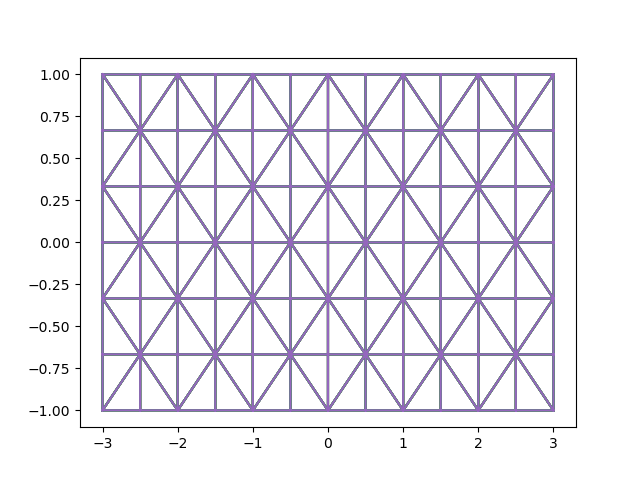

In [56]:
frame = -7
solve.plot_frame(frame)
# solve.animate()

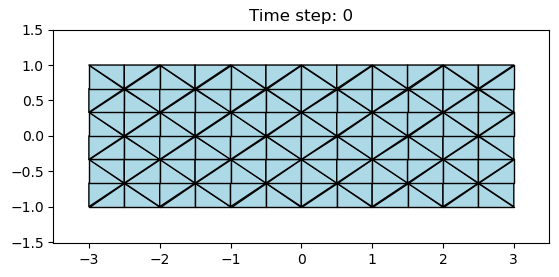

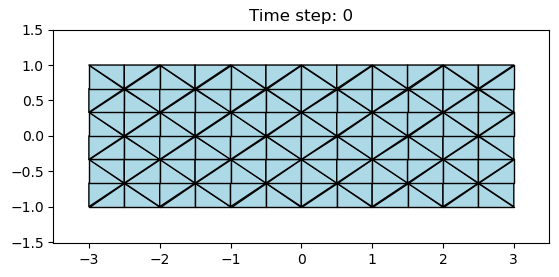

In [57]:
solve.animate()